In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [10]:
#dados do usuário
carteira = ''
ativos = [('1832421D CN', 1436.22), ('1SANPN', 1436.22), ('2458693D US',1436.22), ('IGSN14 CDIE', 10000)]
classificacao = ''

In [11]:
barema_por_ativo = pd.read_csv('../data/processed/barema_por_ativo.csv')
barema_por_ativo

,NOME ATIVO,CLASSIFICACAO DO ATIVO
0,1832421D CN,Renda Variável
1,1SANPN,Renda Variável
2,2299955D CN,Renda Variável
3,2458693D US,Renda Variável
4,700 HK,Renda Variável
...,...,...
8041,ZAVI11,Renda Variável
8042,ZIFI11,Renda Variável
8043,ZS US,Renda Variável
8044,ZTO US,Renda Variável


Distribuição Financeira de Investimentos do Usuário:
Valores:
CLASSIFICACAO DO ATIVO
Renda Fixa        10000.00
Renda Variável     4308.66
Name: VALOR INVESTIDO, dtype: float64

Percentual:
CLASSIFICACAO DO ATIVO
Renda Fixa        69.89
Renda Variável    30.11
Name: VALOR INVESTIDO, dtype: float64%


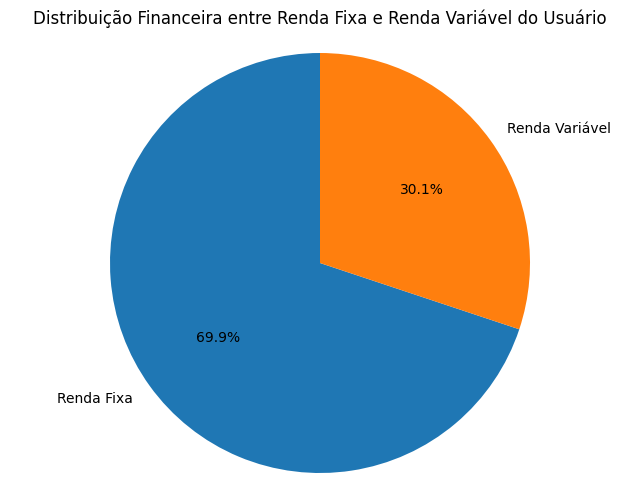

In [12]:
# Create a dictionary from ativos for easy lookup of investment amounts
ativos_dict = {item[0]: item[1] for item in ativos}

# Filter barema_por_ativo for only the user's assets
filtered_barema = barema_por_ativo[barema_por_ativo['NOME ATIVO'].isin(ativos_dict.keys())].copy()

# If no assets found, handle this case
if filtered_barema.empty:
    print("Nenhum dos ativos do usuário foi encontrado no barema.")
else:
    # Add investment amount column
    filtered_barema['VALOR INVESTIDO'] = filtered_barema['NOME ATIVO'].map(ativos_dict)

    # Group by classification and sum the investment amounts
    distribuicao_financeira = filtered_barema.groupby('CLASSIFICACAO DO ATIVO')['VALOR INVESTIDO'].sum()

    # Calculate total investment
    total_investido = distribuicao_financeira.sum()

    # Calculate percentages
    percentual_financeiro = (distribuicao_financeira / total_investido * 100).round(2)

    # Display the results
    print("Distribuição Financeira de Investimentos do Usuário:")
    print(f"Valores:\n{distribuicao_financeira}")
    print(f"\nPercentual:\n{percentual_financeiro}%")

    # Visualize with a pie chart
    plt.figure(figsize=(8, 6))
    plt.pie(distribuicao_financeira, labels=distribuicao_financeira.index, autopct='%1.1f%%', startangle=90)
    plt.axis('equal')
    plt.title('Distribuição Financeira entre Renda Fixa e Renda Variável do Usuário')
    plt.show()